# 13 · Faulted corner-point grid and CO2 vertical-equilibrium migration

A small synthetic faulted block, built in code (no external data), used two ways:

1. **3D corner-point flow.** The grid is a corner-point (GRDECL-layout) block with a normal fault. Two-point flux
   (TPFA) transmissibilities connect the cells across the fault by their overlapping face areas
   (non-neighbour connections). A fully implicit (FIM) water injection then runs from the upthrown block across
   the fault to a producer in the downthrown block.
2. **2D CO2 vertical equilibrium (VE).** The top surface of the same grid becomes a 2D VE grid. CO2 is injected
   into the downthrown block and migrates up the caprock. The run reports structural (spill-point) trapping,
   residual trapping, the CO2 still mobile and the CO2 that leaves through the open edges.

Method notes and validation numbers are in `docs/cornerpoint_and_ve.md`. The VE model follows the published
MRST-co2lab methods (Nilsen et al. 2011, 2015, 2016), and its sharp-interface relative permeabilities are
derived from MRST (GPL-3.0-or-later). **Experimental.** All numbers and figures below come from the compiled
solvers run in this notebook.

**Setup**

- Grid: 40 × 24 × 6 cells of 25 × 25 m with 4 m layers. The caprock dips 2 % to the east (+x) and has a dome on the
  upthrown (west) block. A north–south normal fault at x = 500 m throws the east block down 10 m.
- Layers: alternating 200 / 50 mD sand with porosity 0.24 / 0.18, and kv/kh = 0.1.
- FIM run: water–oil, gravity on. The injector is at (5, 12) and the producer at (34, 12), both open in all layers.
  Injection is 10 L/s for 5 years, and the producer holds 20 MPa bottom-hole pressure.
- VE run: CO2 and brine properties come from the CO2–brine module at 10 MPa and 40 °C, with s_wr = 0.1 and
  s_gr = 0.2. The open edges are hydrostatic. CO2 is injected at 1 kg/s for 10 years at (30, 12), and migration is
  followed to 300 years.

In [1]:
import os, time
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display, Image
%matplotlib inline
import subsurfix as sx
from subsurfix import _native as nat
OUT = Path(os.environ.get("SX_EXAMPLE_OUT", "outputs")).resolve()
OUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 80, "savefig.dpi": 110})
MD = 9.869233e-16
YEAR = 365.25 * 86400.0

## Faulted corner-point block
The grid is built from surfaces and the fault is then applied by moving the `ZCORN` depths of every corner east of
x = 500 m down by 10 m. The same arrays are written to GRDECL and read back, as a check of the reader and writer.

In [2]:
NX, NY, NZ, D, DZ = 40, 24, 6, 25.0, 4.0
xs, ys = np.arange(NX + 1) * D, np.arange(NY + 1) * D
X, Y = np.meshgrid(xs, ys)  # node grid, row = j
top = 1000.0 + 0.02 * X - 25.0 * np.exp(-((X - 300.0) ** 2 + (Y - 300.0) ** 2) / (2 * 110.0**2))
surf = np.array([(top + k * DZ).ravel() for k in range(NZ + 1)])
g0 = nat.CornerPointGrid.from_surfaces(xs, ys, surf)
z = np.array(g0.zcorn, dtype=float)
# ZCORN index: (2i+di) + 2NX((2j+dj) + 2NY(2k+dk)); corners with x > 500 m belong to i >= 20.
FAULT_I, THROW = 20, 10.0
xi = np.arange(z.size) % (2 * NX)
z[xi >= 2 * FAULT_I] += THROW
grid = nat.CornerPointGrid(g0.dims, np.array(g0.coord), z, None)
n = NX * NY * NZ
k_layer = np.where(np.arange(NZ) % 2 == 0, 200.0, 50.0)
phi_layer = np.where(np.arange(NZ) % 2 == 0, 0.24, 0.18)
kk = np.repeat(k_layer, NX * NY); phi = np.repeat(phi_layer, NX * NY)
props = {"PERMX": kk, "PERMY": kk, "PERMZ": 0.1 * kk, "PORO": phi}
path = OUT / "nb13_faulted_block.grdecl"
path.write_text(grid.to_grdecl({k: list(v) for k, v in props.items()}))
grid2, props2 = sx.read_cornerpoint_grdecl(path)
model = sx.flow_model_from_grdecl(grid2, props2)
a, b, t = sx.transmissibilities(model)
roundtrip = np.allclose(np.array(grid2.zcorn), z, rtol=0, atol=1e-9)
display(Markdown("\n".join([
    "| Item | Value |", "|---|---|",
    f"| Cells | {n} ({NX} × {NY} × {NZ}) |",
    f"| GRDECL file size | {path.stat().st_size / 1e3:.0f} kB |",
    f"| ZCORN identical after write/read | {roundtrip} |",
    f"| Connections | {len(t)} |",
    f"| of which across the fault (overlap) | {model.n_fault_connections} |",
    f"| Pore volume | {model.pore_volume().sum() / 1e6:.3f} million m³ |",
    f"| Transmissibility range | {t.min():.2e} – {t.max():.2e} m³ |",
])))

| Item | Value |
|---|---|
| Cells | 5760 (40 × 24 × 6) |
| GRDECL file size | 1000 kB |
| ZCORN identical after write/read | True |
| Connections | 15960 |
| of which across the fault (overlap) | 168 |
| Pore volume | 3.024 million m³ |
| Transmissibility range | 9.56e-14 – 1.23e-12 m³ |

### 3D view
The cells are coloured by permeability, with depth exaggerated 5×. The 10 m step at x = 500 m is the fault.

2026-10-31 23:08:17.624 (   0.589s) [    7FC5787B3740]vtkXOpenGLRenderWindow.:1452  WARN| bad X server connection. DISPLAY=


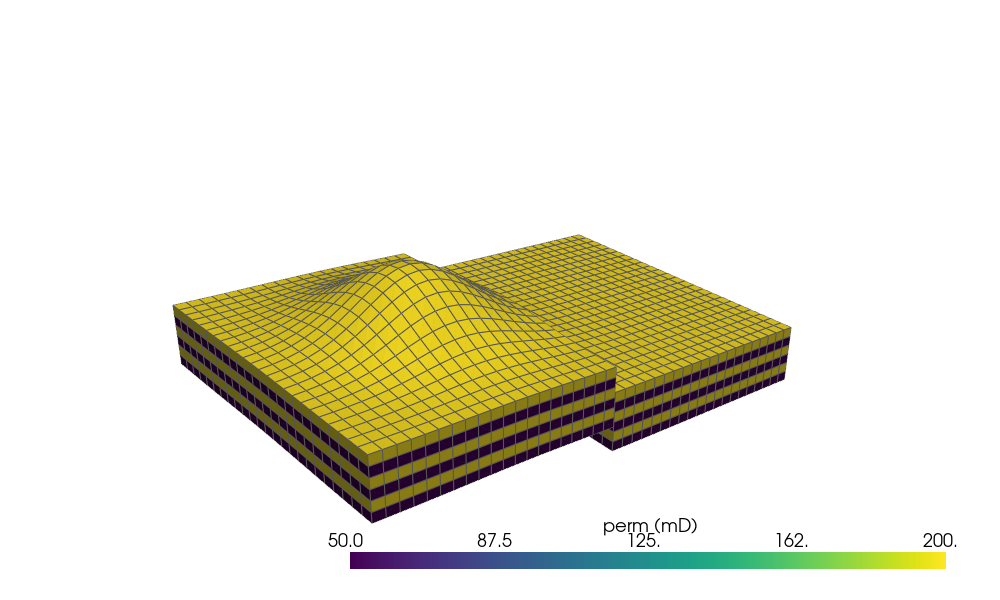

In [3]:
import pyvista as pv
pv.OFF_SCREEN = True
corners = np.array([grid2.corners(c) for c in range(n)]) if hasattr(grid2, "corners") else None
if corners is None:
    # Rebuild corners from ZCORN and the vertical pillars.
    corners = np.zeros((n, 8, 3))
    for c in range(n):
        i, j, k = c % NX, (c // NX) % NY, c // (NX * NY)
        for q in range(8):
            di, dj, dk = q & 1, (q >> 1) & 1, (q >> 2) & 1
            zz = z[(2 * i + di) + 2 * NX * ((2 * j + dj) + 2 * NY * (2 * k + dk))]
            corners[c, q] = (xs[i + di], ys[j + dj], zz)
order = [0, 1, 3, 2, 4, 5, 7, 6]  # corner-point to VTK hexahedron order
pts = corners[:, order, :].reshape(-1, 3).copy()
pts[:, 2] = -5.0 * (pts[:, 2] - 1000.0)
cells = np.hstack([np.full((n, 1), 8), np.arange(8 * n).reshape(n, 8)]).ravel()
ug = pv.UnstructuredGrid(cells, np.full(n, pv.CellType.HEXAHEDRON, dtype=np.uint8), pts)
ug.cell_data["perm (mD)"] = kk
pl = pv.Plotter(off_screen=True, window_size=(1000, 600))
pl.add_mesh(ug, scalars="perm (mD)", show_edges=True, edge_color="#555555", line_width=0.3, cmap="viridis")
pl.camera_position = [(-700, -1100, 900), (500, 300, -40), (0, 0, 1)]
pl.screenshot(OUT / "nb13_faulted_block.png"); pl.close()
display(Image(filename=str(OUT / "nb13_faulted_block.png"), width=750))

## FIM water injection across the fault
This is a dead-oil water–oil run on the corner-point connection list. The injector is in the upthrown block and
the producer is in the downthrown block, so all the water reaching the producer crosses the fault through the
overlap connections.

| Result | Value |
|---|---|
| Run time | 40.5 s |
| Steps / cuts / Newton | 71 / 0 / 336 |
| Worst relative mass-balance error | 1.0e-10 |
| Max Sw east of the fault at 5 yr | 0.725 |
| Water in place east of the fault gained | 509973 m³ (pore volume × ΔSw) |
| INJ bottom-hole pressure at 5 yr | 36.39 MPa |

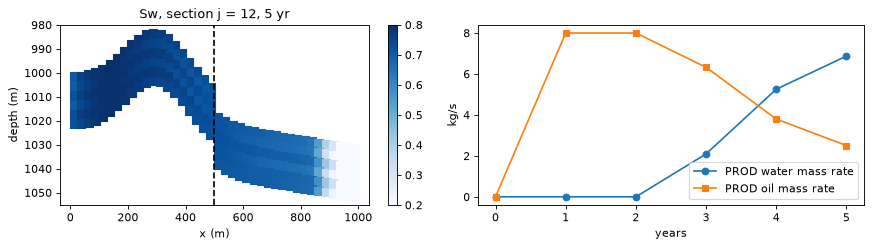

In [4]:
def col(i, j):
    return [i + NX * (j + NY * k) for k in range(NZ)]
wells = [
    {"name": "INJ", "kind": "injector", "rate": 0.01, "cells": col(5, 12)},
    {"name": "PROD", "kind": "producer", "bhp": 2.0e7, "cells": col(34, 12)},
]
times = [y * YEAR for y in (0, 1, 2, 3, 4, 5)]
t0 = time.time()
fim = nat.run_fim_water_oil(model, wells, np.full(n, 0.2), np.full(n, 2.0e7), times,
                            physics={"gravity": 9.80665}, dt_max=30 * 86400.0)
fim_rt = time.time() - t0
mip, net = np.asarray(fim["mass_in_place"]), np.asarray(fim["mass_net_in"])
bal = np.abs((mip - mip[0]) - (net - net[0])).max() / mip[0].sum()
sw = np.asarray(fim["saturation"])[:, :, 0]
east = (np.arange(n) % NX) >= FAULT_I
wr = np.asarray(fim["well_mass_rate"])
display(Markdown("\n".join([
    "| Result | Value |", "|---|---|",
    f"| Run time | {fim_rt:.1f} s |",
    f"| Steps / cuts / Newton | {fim['n_steps']} / {fim['n_cuts']} / {fim['n_newton']} |",
    f"| Worst relative mass-balance error | {bal:.1e} |",
    f"| Max Sw east of the fault at 5 yr | {sw[-1][east].max():.3f} |",
    f"| Water in place east of the fault gained | {(sw[-1][east] - 0.2).clip(0).dot(model.pore_volume()[east]):.0f} m³ (pore volume × ΔSw) |",
    f"| INJ bottom-hole pressure at 5 yr | {np.asarray(fim['bhp'])[-1, 0] / 1e6:.2f} MPa |",
])))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
sec = sw[-1].reshape(NZ, NY, NX)[:, 12, :]
cz = np.array([grid2.centers()[i + NX * (12 + NY * k)][2] for k in range(NZ) for i in range(NX)]).reshape(NZ, NX)
im = ax[0].scatter(np.tile((np.arange(NX) + 0.5) * D, NZ), cz.ravel(), c=sec.ravel(), marker="s", s=60, cmap="Blues", vmin=0.2, vmax=0.8)
ax[0].invert_yaxis(); ax[0].axvline(FAULT_I * D, color="k", ls="--"); ax[0].set_xlabel("x (m)"); ax[0].set_ylabel("depth (m)")
ax[0].set_title("Sw, section j = 12, 5 yr"); fig.colorbar(im, ax=ax[0])
ax[1].plot(np.asarray(fim["times"]) / YEAR, -wr[:, 1, 0], "o-", label="PROD water mass rate")
ax[1].plot(np.asarray(fim["times"]) / YEAR, -wr[:, 1, 1], "s-", label="PROD oil mass rate")
ax[1].set_xlabel("years"); ax[1].set_ylabel("kg/s"); ax[1].legend()
fig.tight_layout(); fig.savefig(OUT / "nb13_fim.png", bbox_inches="tight")

## CO2 vertical-equilibrium migration and trapping
`VeGrid.from_corner_point` collapses each column to its caprock depth, its thickness, a pore-volume-weighted
porosity and a thickness-weighted permeability. A spill-point analysis finds the structural trap under the
dome. The VE run injects CO2 into the downthrown block, stops after 10 years and then follows the plume up
the caprock.

In [5]:
perm3 = np.column_stack([kk, kk, 0.1 * kk]) * MD
vg = sx.VeGrid.from_corner_point(grid2, perm3, phi)
traps = vg.trap_analysis()
fl = nat.ve_fluid_properties(1.0e7, 313.15)
rate_v = 1.0 / fl["rho_co2"]
inj = int(np.nonzero(vg.column == 30 + NX * 12)[0][0])
times_ve = [y * YEAR for y in (5, 10, 25, 50, 100, 200, 300)]
t0 = time.time()
ve = sx.run_co2_ve(vg, [{"cell": inj, "rate": rate_v, "t_end": 10 * YEAR}], times_ve, s_wr=0.1, s_gr=0.2,
                   p_fluid=1.0e7, t_fluid=313.15)
ve_rt = time.time() - t0
inv = np.asarray(ve["inventory"]) / 1e9  # Mt
cap = sum(vg.poro[c] * vg.area[c] * 0.9 * min(traps["fill_depth"][c] - vg.top[c], vg.thickness[c])
          for c in range(vg.n_cells) if traps["trap"][c] >= 0) * fl["rho_co2"] / 1e9
rows = ["| Quantity | Value |", "|---|---|",
        f"| VE cells | {vg.n_cells} |",
        f"| CO2 density / viscosity | {fl['rho_co2']:.1f} kg/m³ / {fl['mu_co2'] * 1e3:.4f} mPa·s |",
        f"| Brine density / viscosity | {fl['rho_brine']:.1f} kg/m³ / {fl['mu_brine'] * 1e3:.4f} mPa·s |",
        f"| Traps found / spill depth | {len(traps['spill_depth'])} / " + ", ".join(f"{s:.2f} m" for s in traps['spill_depth']) + " |",
        f"| Structural capacity (mobile CO2 above spill) | {cap:.3f} Mt |",
        f"| Run time / explicit steps | {ve_rt:.1f} s / {ve['n_steps']} |",
        f"| Worst mass-balance error | {np.abs(inv[:, 0] - inv[:, 1] - inv[:, 5]).max() / inv[:, 0].max():.1e} |"]
display(Markdown("\n".join(rows)))
names = ve["inventory_names"]
tab = ["| Year | " + " | ".join(names) + " |", "|---" * (len(names) + 1) + "|"]
for t, row in zip(ve["times"], inv):
    tab.append(f"| {t / YEAR:.0f} | " + " | ".join(f"{v:.3f}" for v in row) + " |")
display(Markdown("**CO2 inventory (Mt)**\n\n" + "\n".join(tab)))

| Quantity | Value |
|---|---|
| VE cells | 960 |
| CO2 density / viscosity | 563.6 kg/m³ / 0.0414 mPa·s |
| Brine density / viscosity | 996.5 kg/m³ / 0.6540 mPa·s |
| Traps found / spill depth | 1 / 999.41 m |
| Structural capacity (mobile CO2 above spill) | 0.082 Mt |
| Run time / explicit steps | 59.0 s / 135133 |
| Worst mass-balance error | 1.7e-13 |

**CO2 inventory (Mt)**

| Year | injected | in_place | residual | structural | free_plume | exited |
|---|---|---|---|---|---|---|
| 5 | 0.158 | 0.120 | 0.000 | 0.026 | 0.093 | 0.038 |
| 10 | 0.316 | 0.199 | 0.000 | 0.076 | 0.123 | 0.116 |
| 25 | 0.316 | 0.156 | 0.027 | 0.082 | 0.048 | 0.159 |
| 50 | 0.316 | 0.133 | 0.034 | 0.082 | 0.017 | 0.183 |
| 100 | 0.316 | 0.124 | 0.036 | 0.082 | 0.007 | 0.191 |
| 200 | 0.316 | 0.121 | 0.037 | 0.082 | 0.003 | 0.194 |
| 300 | 0.316 | 0.121 | 0.037 | 0.082 | 0.002 | 0.195 |

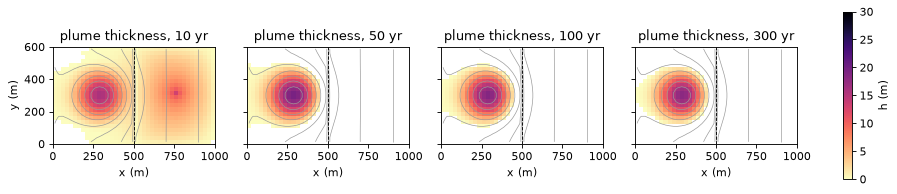

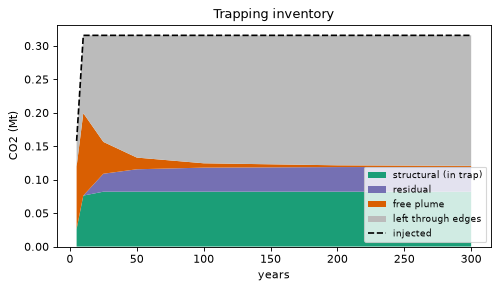

In [6]:
cx = vg.centers()
fig, axs = plt.subplots(1, 4, figsize=(15, 3.4), sharey=True)
for ax, ti in zip(axs, [1, 3, 4, 6]):
    hmap = np.full(NX * NY, np.nan); hmap[vg.column] = np.asarray(ve["h"])[ti]
    topm = np.full(NX * NY, np.nan); topm[vg.column] = vg.top
    ax.contour((np.arange(NX) + 0.5) * D, (np.arange(NY) + 0.5) * D, topm.reshape(NY, NX), 12, colors="0.6", linewidths=0.6)
    im = ax.pcolormesh(xs, ys, np.ma.masked_less(hmap.reshape(NY, NX), 0.01), cmap="magma_r", vmin=0, vmax=30)
    ax.axvline(FAULT_I * D, color="k", ls="--", lw=0.8)
    ax.set_title(f"plume thickness, {ve['times'][ti] / YEAR:.0f} yr"); ax.set_xlabel("x (m)"); ax.set_aspect("equal")
axs[0].set_ylabel("y (m)"); fig.colorbar(im, ax=axs, label="h (m)", shrink=0.8)
fig.savefig(OUT / "nb13_ve_plume.png", bbox_inches="tight")
fig, ax = plt.subplots(figsize=(7, 3.6))
yrs = np.asarray(ve["times"]) / YEAR
ax.stackplot(yrs, inv[:, 3], inv[:, 2], inv[:, 4], inv[:, 5],
             labels=["structural (in trap)", "residual", "free plume", "left through edges"],
             colors=["#1b9e77", "#7570b3", "#d95f02", "#bbbbbb"])
ax.plot(yrs, inv[:, 0], "k--", label="injected")
ax.set_xlabel("years"); ax.set_ylabel("CO2 (Mt)"); ax.legend(fontsize=8, loc="lower right"); ax.set_title("Trapping inventory")
fig.savefig(OUT / "nb13_ve_inventory.png", bbox_inches="tight")

## Same CO2 case with the full 3D solver (FIM-OBL) and VE
Both methods answer "where does the injected CO2 go?", at very different cost. VE treats the reservoir as one
thin layer under the caprock and moves only the plume thickness; the fully implicit solver (FIM-OBL, the default
SubsurfiX solver) solves pressure and composition in every 3D cell, including CO2 dissolving into brine.

Here both inject CO2 at 1 kg/s at column (30, 12) on the same faulted corner-point grid, and both are compared
over the 10 injection years only (the FIM run has no well shut-in schedule, so it is not continued into the
migration period). Setup of the FIM run: CO2–brine at 40 °C without salt, gravity on, hydrostatic start
pressure (10 MPa at the shallowest cell centre), and four brine producers in the corner columns held at their
starting pressure, standing in for VE's open hydrostatic edges.

| Quantity at 10 years | VE | FIM-OBL |
|---|---|---|
| Cells solved | 960 columns | 5760 cells |
| Run time | 2.38 s | 67.0 s |
| Plume footprint (map area with CO2) | 55.2 ha | 39.2 ha |
| Farthest plume edge from INJ | 765 m | 629 m |
| Max plume thickness / max CO2 saturation | 15.7 m | 1.00 |
| CO2 in the model | 0.199 Mt (exited: 0.116 Mt) | 0.245 Mt (incl. dissolved) |
| Mass-balance error | 1.1e-14 | 8.8e-10 |

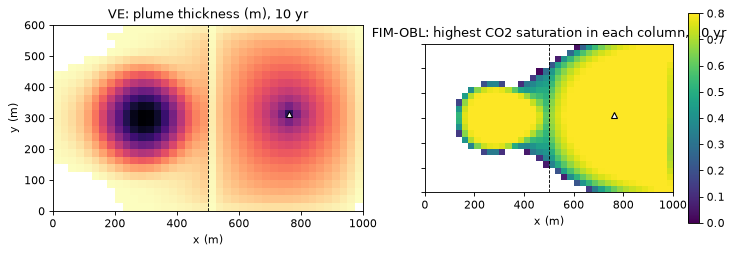

In [7]:
zc = np.asarray(grid2.centers())[:, 2]
p_hyd = 1.0e7 + 1000.0 * 9.80665 * (zc - zc.min())
t0 = time.time()
ve10 = sx.run_co2_ve(vg, [{"cell": inj, "rate": rate_v, "t_end": 10 * YEAR}], [5 * YEAR, 10 * YEAR],
                     s_wr=0.1, s_gr=0.2, p_fluid=1.0e7, t_fluid=313.15)
ve10_rt = time.time() - t0
cw = [{"name": "INJ", "kind": "injector", "rate": rate_v, "cells": col(30, 12)}]
for nm, (ci, cj) in zip(("P1", "P2", "P3", "P4"), ((0, 0), (NX - 1, 0), (0, NY - 1), (NX - 1, NY - 1))):
    cc = col(ci, cj)
    cw.append({"name": nm, "kind": "producer", "bhp": float(p_hyd[cc[0]]), "cells": cc})
t0 = time.time()
fco = nat.run_fim_co2_brine(model, cw, p_hyd, np.full(n, 1e-6), [0.0, 5 * YEAR, 10 * YEAR], temperature=313.15,
                            m_nacl=0.0, gravity=9.80665, s_res=(0.1, 0.2), p_range=(5e6, 3e7),
                            table_points=[61, 201], dt_init=86400.0, dt_max=0.1 * YEAR)
fco_rt = time.time() - t0
sg = np.asarray(fco["saturation"])[-1, :, 1].reshape(NZ, NY, NX)
foot_fim = (sg > 0.01).any(axis=0)
hmap = np.full(NX * NY, 0.0); hmap[vg.column] = np.asarray(ve10["h"])[-1]
foot_ve = hmap.reshape(NY, NX) > 0.01
ix, iy = np.meshgrid((np.arange(NX) + 0.5) * D, (np.arange(NY) + 0.5) * D)
r = np.hypot(ix - 30.5 * D, iy - 12.5 * D)
mip = np.asarray(fco["mass_in_place"]); mni = np.asarray(fco["mass_net_in"])
co2_fim = (mip[-1, 0] - mip[0, 0]) / 1e9
bal_fim = np.abs((mip[1:] - mip[0]) - mni[1:]).max() / np.abs(mni[1:]).max()
inv10 = np.asarray(ve10["inventory"])[-1] / 1e9
names = ve10["inventory_names"]
rows = ["| Quantity at 10 years | VE | FIM-OBL |", "|---|---|---|",
        f"| Cells solved | {vg.n_cells} columns | {n} cells |",
        f"| Run time | {ve10_rt:.2f} s | {fco_rt:.1f} s |",
        f"| Plume footprint (map area with CO2) | {foot_ve.sum() * D * D / 1e4:.1f} ha | {foot_fim.sum() * D * D / 1e4:.1f} ha |",
        f"| Farthest plume edge from INJ | {r[foot_ve].max():.0f} m | {r[foot_fim].max():.0f} m |",
        f"| Max plume thickness / max CO2 saturation | {hmap.max():.1f} m | {sg.max():.2f} |",
        f"| CO2 in the model | {inv10[0] - inv10[5]:.3f} Mt ({names[5]}: {inv10[5]:.3f} Mt) | {co2_fim:.3f} Mt (incl. dissolved) |",
        f"| Mass-balance error | {np.abs(np.asarray(ve10['inventory'])[:, 0] - np.asarray(ve10['inventory'])[:, 1] - np.asarray(ve10['inventory'])[:, 5]).max() / np.asarray(ve10['inventory'])[:, 0].max():.1e} | {bal_fim:.1e} |"]
display(Markdown("\n".join(rows)))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
ax[0].pcolormesh(xs, ys, np.ma.masked_less(hmap.reshape(NY, NX), 0.01), cmap="magma_r", vmin=0, vmax=max(hmap.max(), 1))
ax[0].set_title("VE: plume thickness (m), 10 yr")
im = ax[1].pcolormesh(xs, ys, np.ma.masked_less(sg.max(axis=0), 0.01), cmap="viridis", vmin=0, vmax=0.8)
ax[1].set_title("FIM-OBL: highest CO2 saturation in each column, 10 yr"); fig.colorbar(im, ax=ax[1])
for a in ax:
    a.axvline(FAULT_I * D, color="k", ls="--", lw=0.8); a.plot(30.5 * D, 12.5 * D, "w^", mec="k"); a.set_aspect("equal")
    a.set_xlabel("x (m)")
ax[0].set_ylabel("y (m)")
fig.savefig(OUT / "nb13_ve_vs_fim.png", bbox_inches="tight")

**Reading the comparison.** The table and maps above are measured, not tuned. Both mass-balance errors are relative
to the CO2 injected (kg against kg). The FIM-OBL maximum CO2 saturation of 1.00 is most likely dry-out next to
the injector: dry CO2 keeps flowing through those cells and evaporates the remaining brine (water dissolves into
the CO2 phase), so the brine saturation can drop below its residual value of 0.1. VE has no evaporation and keeps
the residual brine. (Not yet checked cell by cell.) VE is much faster because it
solves one value per map column with explicit steps; FIM-OBL solves every 3D cell and also lets CO2 dissolve
into the brine, so it holds part of the CO2 out of the free plume. Use VE to screen where stored CO2 goes over
decades and how much is trapped; use FIM-OBL when the 3D layering, dissolution or pressure matter.
In this run VE's plume covers more map area (55 vs 39 ha) because it spreads as a thin layer under the
caprock, and more of VE's CO2 leaves through its open edges (0.116 Mt) than FIM-OBL's producers remove.

## Limitations
- Faults in the 3D model are geometric overlaps only. There are no fault-rock transmissibility multipliers unless
  `MULT*` arrays are given, and no MRST exact face splitting, `MINPV`/`PINCH` or `MAPAXES`.
- The VE grid connects columns by logical (i, j) neighbours. Across the fault it sees only the step in caprock
  depth, not juxtaposition or a sealing fault.
- VE physics is a sharp interface with constant (incompressible) densities and viscosities, with no capillary
  fringe, no CO2 dissolution or convective mixing, and no caprock rugosity. Residual trapping uses a single s_gr
  without hysteresis curves.
- Explicit (IMPES) time stepping is limited by a CFL condition, so long migrations on fine grids need many
  steps.
- Experimental: checked against analytic solutions (see docs), not run against MRST-co2lab on this model.